# FunkSVD: sensibilidad, selección y evaluación reproducible

**Equipo:** Grupo 18 (eight nine)  
**Integrantes:** Jorge Cartagena y Santiago Valenzuela  
**Uso de IA:** registro y enlaces en [`USO_IA.md`](../USO_IA.md).

Se conserva este notebook como punto de entrada del método. El experimento usa todas las interacciones de entrenamiento y validación y exporta sus tablas, figuras y protocolo a `tarea_01/informe_assets`.

Comparamos 20, 50 y 100 factores, dos tasas de aprendizaje y dos regularizaciones, con sesgos, 30 épocas y semilla 42. Se optimiza error de rating; el mejor ranking se identifica por separado.

La selección de hiperparámetros usa validación: los resultados son exploratorios, sin test independiente. Semilla 42 es una decisión del experimento.

In [1]:
import sys
from pathlib import Path

project_root = next(
    p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (p / "tarea_01" / "utils.py").exists()
)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import pandas as pd
from IPython.display import Image, display

from tarea_01.experiments_item_funksvd import run_family
from tarea_01.plot_item_funksvd_results import (
    plot_family_ranking,
    plot_family_sensitivity,
)

output_dir = project_root / "tarea_01" / "informe_assets" / "data"
figure_dir = output_dir.parent
SEED = 42
NEGATIVES = 100
K = 10
THRESHOLD = 4.0

## Entrenamiento y grilla completa

Se ejecuta la misma implementación que usa el comando reproducible del README. Los CSV conservan precisión completa; el redondeo solo afecta la presentación. Cada configuración se evalúa en rating y ranking con los mismos candidatos.

In [2]:
experiment = run_family(
    "FunkSVD",
    output_dir=output_dir,
    random_state=SEED,
    ranking_negatives=NEGATIVES,
    top_k=K,
    relevance_threshold=THRESHOLD,
)
sensitivity = experiment["sensitivity"]
config_columns = ["n_factors", "n_epochs", "lr_all", "reg_all", "biased"]
sensitivity[config_columns + ["RMSE", "MAE", "Recall@10", "NDCG@10", "MAP@10"]].round(6)

funk_f20_lr0.003_reg0.02_bias1_e30_s42: RMSE=0.885062, MAE=0.481179


funk_f20_lr0.003_reg0.05_bias1_e30_s42: RMSE=0.884058, MAE=0.481343


funk_f20_lr0.005_reg0.02_bias1_e30_s42: RMSE=0.890541, MAE=0.482049


funk_f20_lr0.005_reg0.05_bias1_e30_s42: RMSE=0.887271, MAE=0.480764


funk_f50_lr0.003_reg0.02_bias1_e30_s42: RMSE=0.886812, MAE=0.483269


...

funk_f100_lr0.003_reg0.02_bias1_e30_s42: RMSE=0.888725, MAE=0.485410


funk_f100_lr0.003_reg0.05_bias1_e30_s42: RMSE=0.886272, MAE=0.483954


funk_f100_lr0.005_reg0.02_bias1_e30_s42: RMSE=0.895658, MAE=0.488031


funk_f100_lr0.005_reg0.05_bias1_e30_s42: RMSE=0.890003, MAE=0.483897


,n_factors,n_epochs,lr_all,reg_all,biased,RMSE,MAE,Recall@10,NDCG@10,MAP@10
0,20,30,0.003,0.02,True,0.885062,0.481179,0.118986,0.097102,0.045904
1,20,30,0.003,0.05,True,0.884058,0.481343,0.115573,0.093230,0.043560
2,20,30,0.005,0.02,True,0.890541,0.482049,0.110380,0.088989,0.041060
3,20,30,0.005,0.05,True,0.887271,0.480764,0.101891,0.080424,0.036294
4,50,30,0.003,0.02,True,0.886812,0.483269,0.114443,0.096537,0.046347
5,50,30,0.003,0.05,True,0.884869,0.482505,0.109829,0.091438,0.043249
6,50,30,0.005,0.02,True,0.894162,0.485976,0.113505,0.094183,0.044659
7,50,30,0.005,0.05,True,0.888725,0.482661,0.102661,0.082913,0.038048
8,100,30,0.003,0.02,True,0.888725,0.485410,0.109374,0.091794,0.043436
9,100,30,0.003,0.05,True,0.886272,0.483954,0.103123,0.084473,0.039013


## Sensibilidad y elección del objetivo

Las curvas muestran qué cambia al aumentar capacidad, manteniendo identificables los demás hiperparámetros. Los ejes de error y ranking usan zoom; hay que interpretar los cambios absolutos indicados, no solo la pendiente visual.

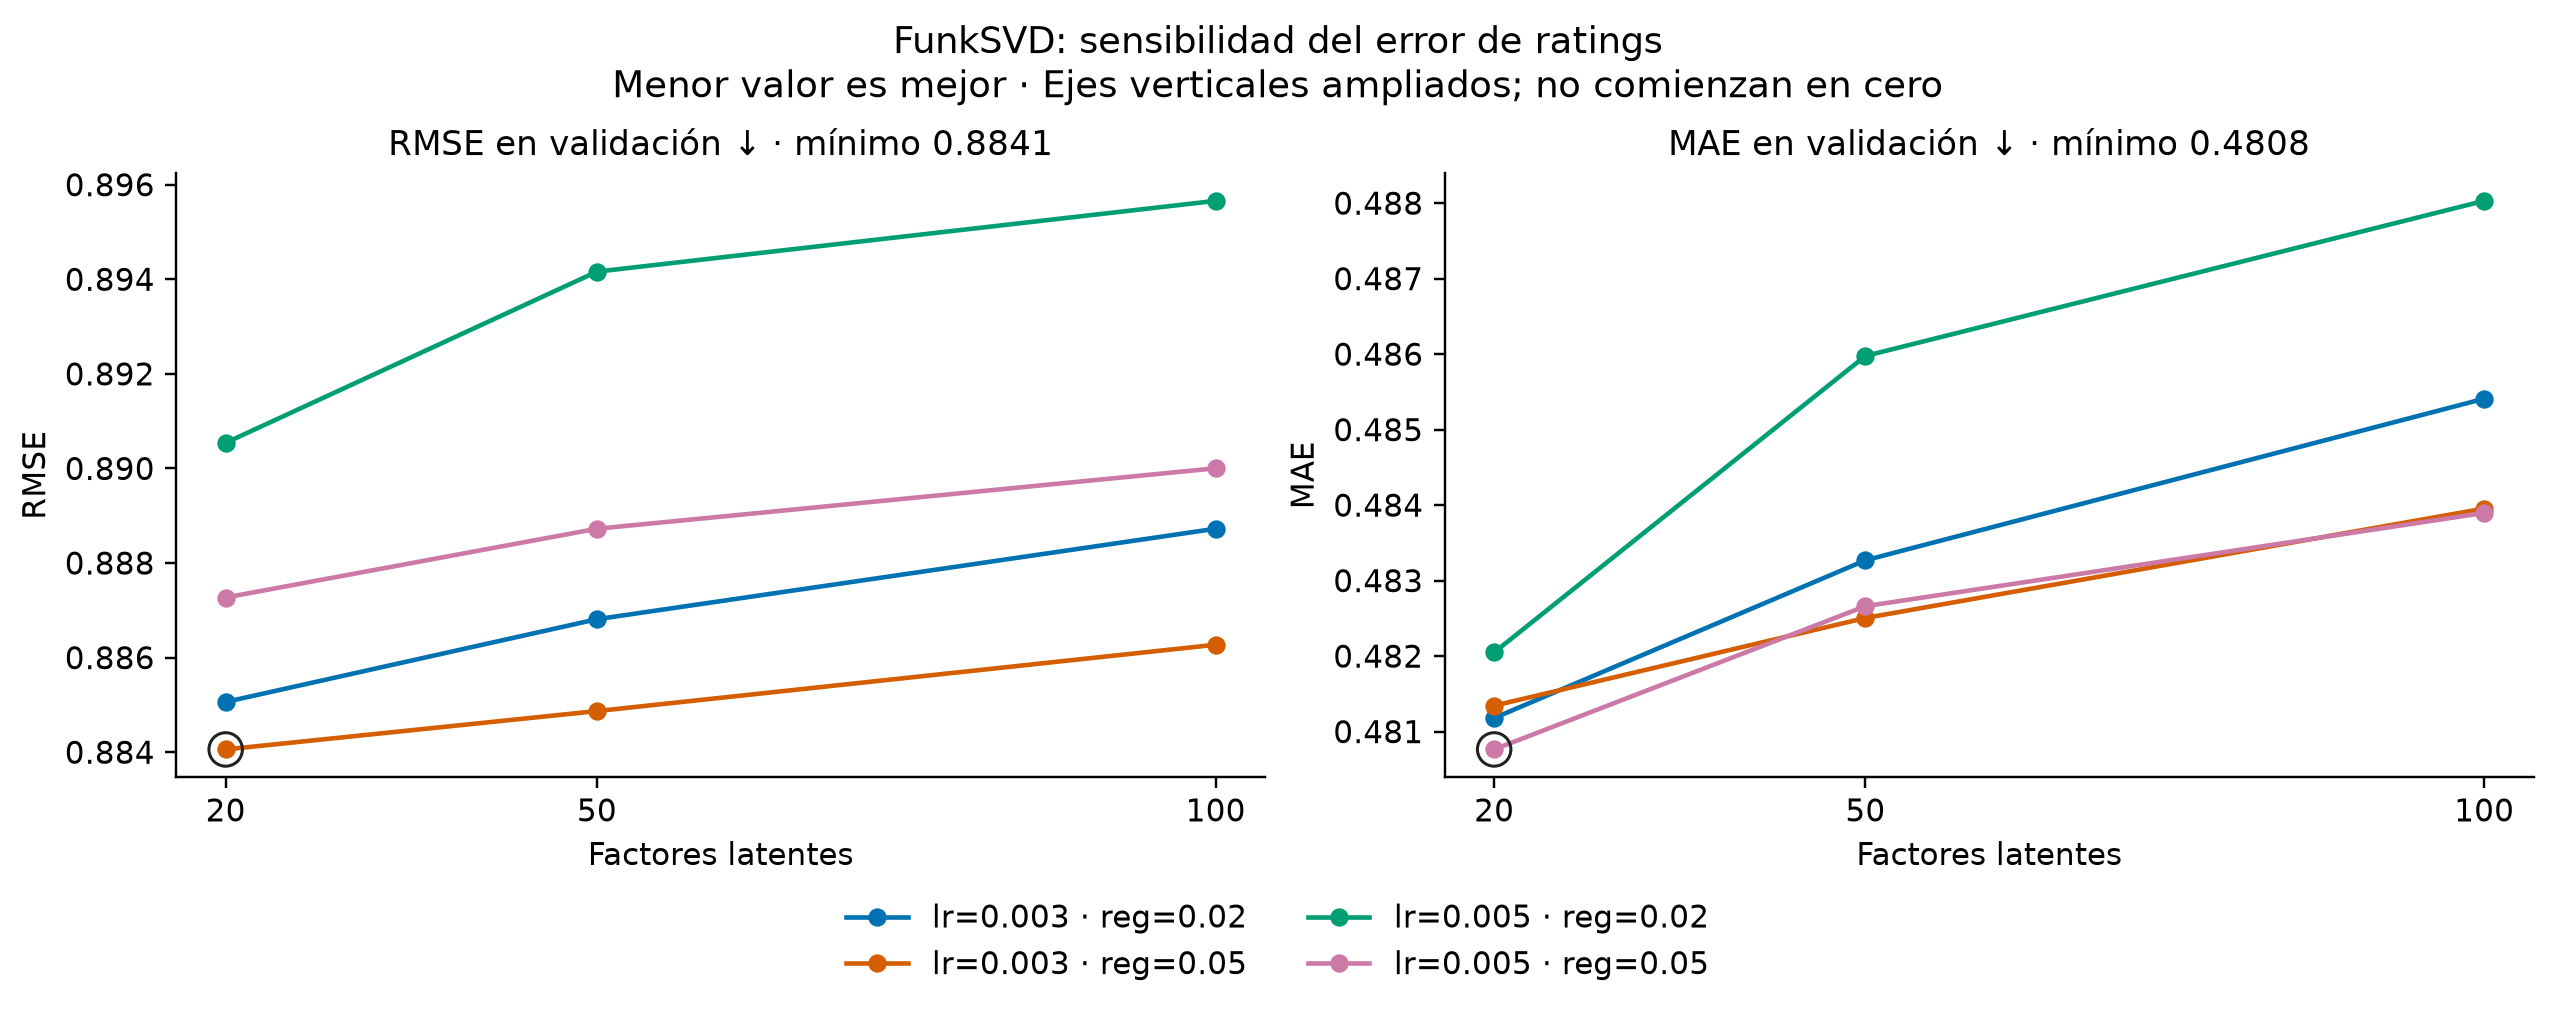

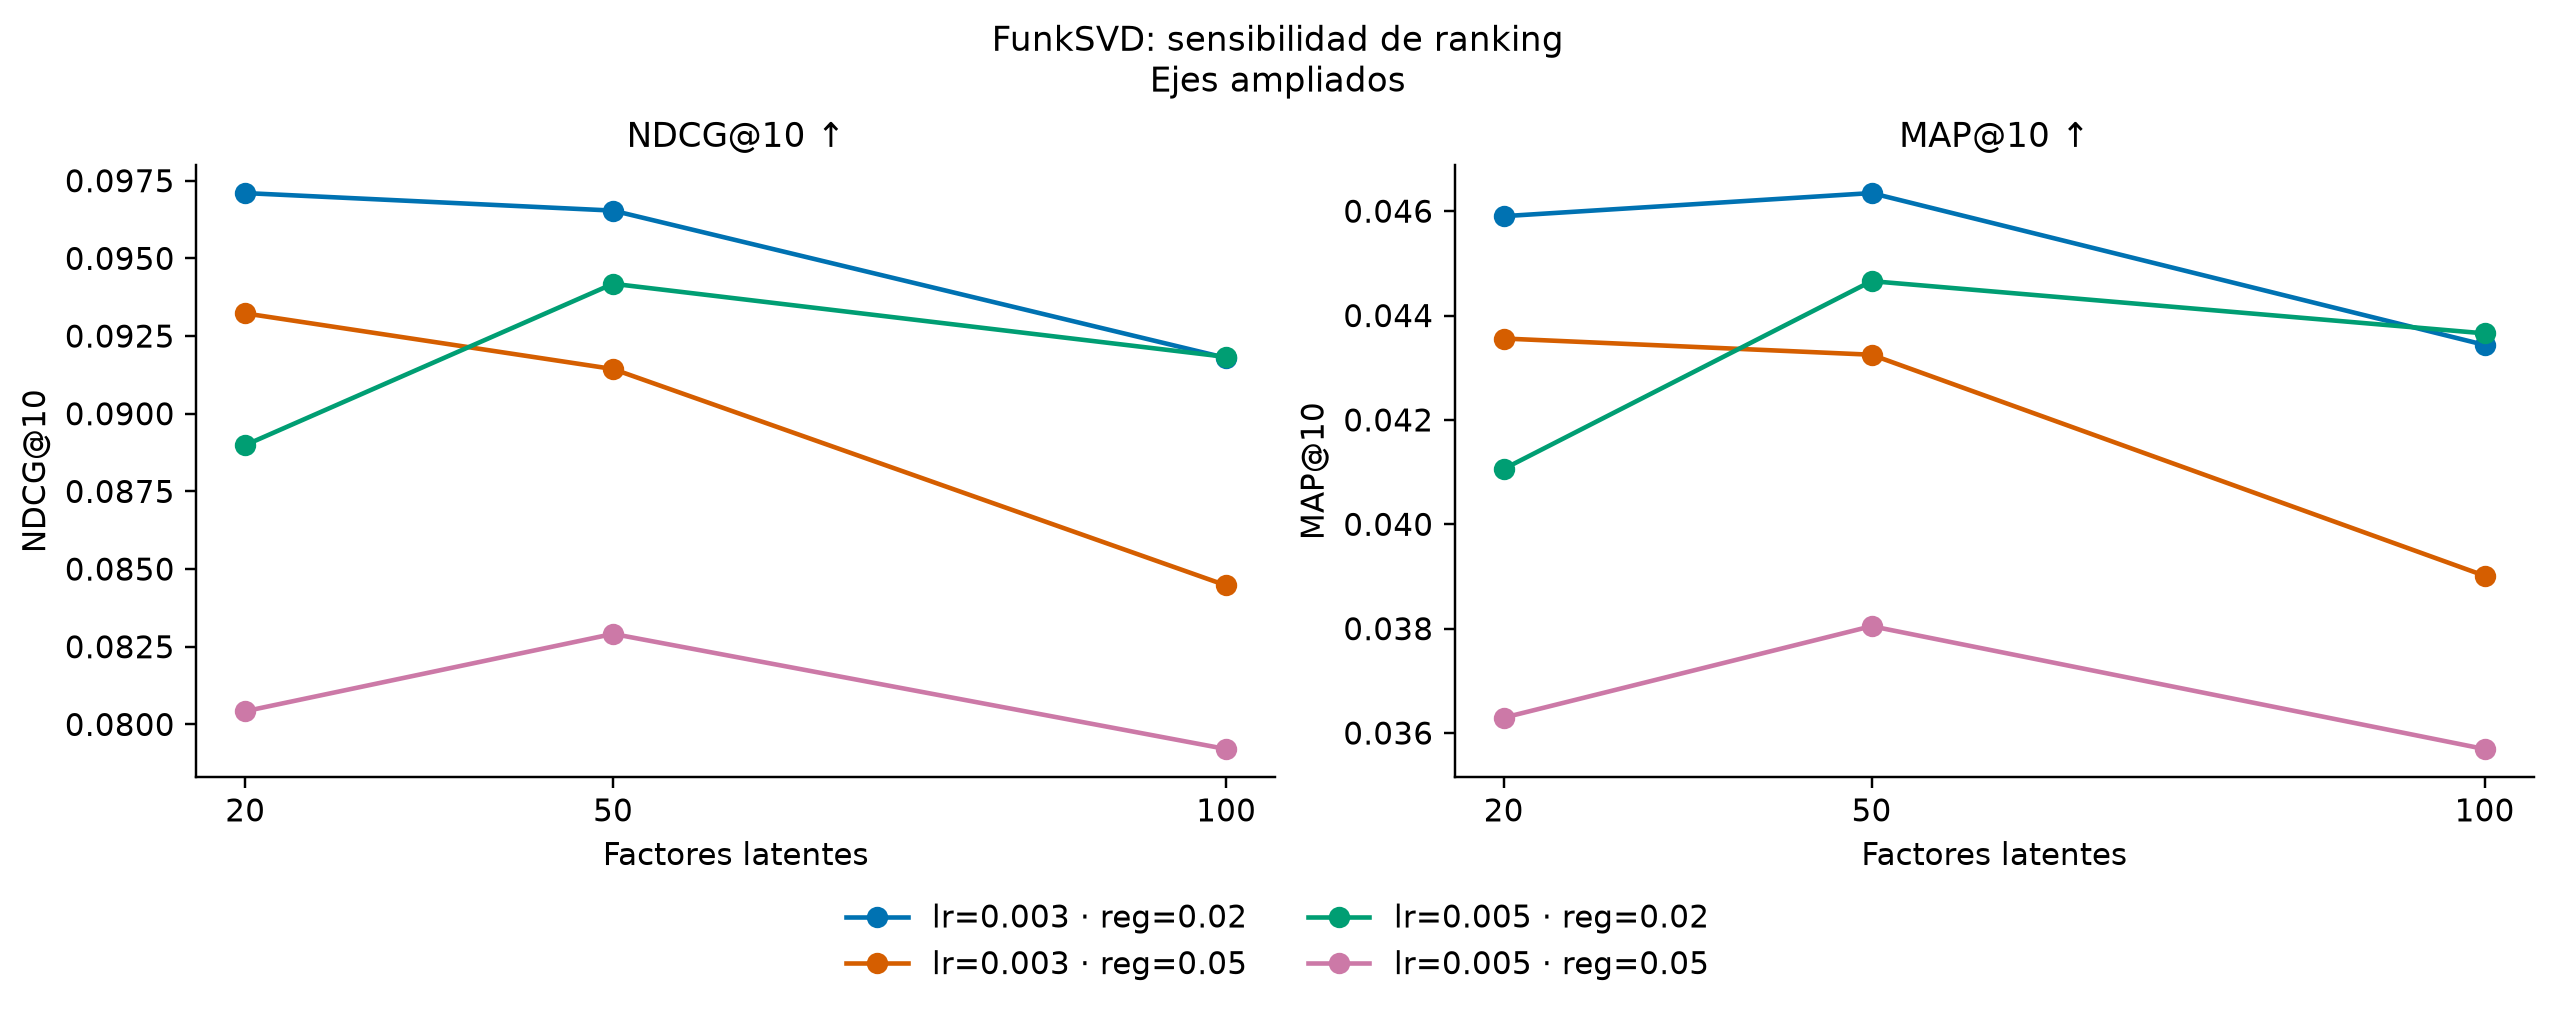

In [3]:
figure_path = plot_family_sensitivity(sensitivity, "FunkSVD", figure_dir)
display(Image(filename=figure_path))
ranking_path = plot_family_ranking(sensitivity, "FunkSVD", figure_dir)
display(Image(filename=ranking_path))

In [4]:
objectives = {"RMSE": "min", "MAE": "min", "NDCG@10": "max"}
choices = []
for metric, direction in objectives.items():
    index = sensitivity[metric].idxmin() if direction == "min" else sensitivity[metric].idxmax()
    row = sensitivity.loc[index]
    choices.append({"Objetivo": metric, **row[config_columns + ["RMSE", "MAE", "NDCG@10"]].to_dict()})
pd.DataFrame(choices).round(6)

,Objetivo,n_factors,n_epochs,lr_all,reg_all,biased,RMSE,MAE,NDCG@10
0,RMSE,20,30,0.003,0.05,True,0.884058,0.481343,0.093230
1,MAE,20,30,0.005,0.05,True,0.887271,0.480764,0.080424
2,NDCG@10,20,30,0.003,0.02,True,0.885062,0.481179,0.097102


## Top-10 y métricas de descubrimiento

Se incluyen **todas las interacciones de validación**, incluso ratings menores que 4, y 100 recetas no vistas por usuario. Se excluyen las recetas vistas en entrenamiento. Los scores de ranking no se recortan; en empates se usa recipe_id ascendente, sin consultar la relevancia. RMSE y MAE usan únicamente ratings reales, recortados a [0,5].

`TagDiversity` cuenta tags distintos por lista; se informa como aproximación operativa a variedad de contenido, sin afirmar que cada tag es un estilo culinario. `InteractionILD` mide disimilitud colaborativa. La novedad se muestra en bits por ítem y por lista. Esta evaluación muestreada no equivale a usar todo el catálogo.

In [5]:
evaluation = experiment["evaluation"]
pd.DataFrame([evaluation.metrics], index=["FunkSVD: elegido por RMSE"]).T

,FunkSVD: elegido por RMSE
RMSE,0.884058
MAE,0.481343
Precision@10,0.061489
Recall@10,0.115573
NDCG@10,0.093230
MAP@10,0.043560
InteractionILD,0.984600
TagDiversity,92.263917
TagMetadataCoverage,1.000000
NoveltyBitsPerList,129.148591


## Evidencia de la selección

Los siguientes registros permiten inspeccionar usuarios concretos y corroborar el ranking; los archivos exportados incluyen el conjunto de candidatos identificado por hash. Los hallazgos del informe deben referirse a este protocolo y a estas configuraciones.

In [6]:
display(evaluation.per_user.head())
display(evaluation.top_k.head(10))
evaluation.protocol

,user_id,Candidates,RelevantItems,HasRelevant,RecommendedItems,Hits,Precision@10,Recall@10,NDCG@10,MAP@10,...,TagMetadataCoverage,NoveltyBitsPerItem,NoveltyBitsPerList,NoveltyKnownItemFraction,RankingFallbackFraction,RankingTiedCandidateFraction,RankingTieAt10,ActualKMean,ActualKMin,TrainInteractions
0,1533,104,4,True,10,0,0.0,0.000000,0.000000,0.000000,...,1.0,13.271613,132.716132,1.0,0.0,0.0,False,NaN,NaN,11
1,1535,114,13,True,10,1,0.1,0.076923,0.138862,0.050000,...,1.0,12.903950,129.039502,1.0,0.0,0.0,False,NaN,NaN,202
2,1891,102,2,True,10,0,0.0,0.000000,0.000000,0.000000,...,1.0,12.902871,129.028706,1.0,0.0,0.0,False,NaN,NaN,16
3,2310,109,9,True,10,1,0.1,0.111111,0.067943,0.011111,...,1.0,12.975300,129.753000,1.0,0.0,0.0,False,NaN,NaN,53
4,2312,105,5,True,10,1,0.1,0.200000,0.106993,0.025000,...,1.0,12.982784,129.827839,1.0,0.0,0.0,False,NaN,NaN,28


,user_id,recipe_id,true_rating,is_validation,is_relevant,score,raw_score,rating_est,was_impossible,actual_k,outside_rating_scale,rank,train_count,self_information_bits,metadata_tags_known
0,1533,23481,0.0,False,False,4.927880,4.927880,4.927880,False,None,False,1,12,13.676435,True
1,1533,304705,0.0,False,False,4.901496,4.901496,4.901496,False,None,False,2,12,13.676435,True
2,1533,193851,0.0,False,False,4.896665,4.896665,4.896665,False,None,False,3,21,12.869080,True
3,1533,245266,0.0,False,False,4.887251,4.887251,4.887251,False,None,False,4,15,13.354507,True
4,1533,26987,0.0,False,False,4.885799,4.885799,4.885799,False,None,False,5,14,13.454042,True
5,1533,88880,0.0,False,False,4.871720,4.871720,4.871720,False,None,False,6,47,11.706808,True
6,1533,61982,0.0,False,False,4.870907,4.870907,4.870907,False,None,False,7,12,13.676435,True
7,1533,69213,0.0,False,False,4.866178,4.866178,4.866178,False,None,False,8,26,12.560957,True
8,1533,266362,0.0,False,False,4.851504,4.851504,4.851504,False,None,False,9,11,13.801966,True
9,1533,127820,0.0,False,False,4.850099,4.850099,4.850099,False,None,False,10,10,13.939469,True


{'protocol_version': 'validation-unseen-v2-raw-score-item-id-ties',
 'ranking_candidate_mode': 'negative_sample_100',
 'k': 10,
 'relevance_threshold': 4.0,
 'n_negatives': 100,
 'seed': 42,
 'sampler': 'numpy.default_rng; sorted users and catalog; without replacement',
 'tie_break': 'score descending, raw item ID ascending',
 'validation_items': 'all observed validation items, including ratings below threshold',
 'unobserved_relevance': 'unknown, treated as zero for offline ranking',
 'accuracy_population': 'macro mean over users with at least one relevant validation item',
 'beyond_accuracy_population': 'all evaluated users',
 'precision_denominator': 10,
 'map_denominator': 'min(k, number of relevant validation items)',
 'novelty_probability': 'training item observation count / training observation count',
 'interaction_ild': 'mean pairwise 1-cosine of binary training item-user vectors',
 'tag_diversity': 'mean distinct raw metadata tags in each recommendation list',
 'unknown_metad

## Fuentes y límites

[SVD con y sin sesgos, documentación oficial](https://surprise.readthedocs.io/en/stable/matrix_factorization.html). [Métricas con candidatos muestreados](https://arxiv.org/abs/1912.02263).

La grilla no prueba que el método ganador lo sea en todo escenario; la semilla fija permite repetir la corrida, pero no reemplaza un análisis de variabilidad. El consolidado usa la configuración elegida por RMSE y distingue este criterio de una selección por nDCG.